# artifacts: DINOv2 patch tokens + MIL

Проверяем, помогают ли отдельные участки рендеров находить повреждения. DINOv2 заморожен, обучается только небольшая голова.

Первый прогон выполнен в Colab: ниже сохранены его результаты и карты внимания. В конце добавлена проверка attention по эпохам — она ещё не выполнена.

## 1. Данные

In [ ]:
%pip install -q iterative-stratification

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import random
import shutil
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_score, recall_score
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
assert torch.cuda.is_available(), 'В Colab включи GPU: Runtime → Change runtime type → T4 GPU'
device = torch.device('cuda')

from google.colab import drive
drive.mount('/content/drive')
paths = [Path.cwd(), *Path.cwd().parents,
         Path('/content/drive/MyDrive/Colab Notebooks/colab_upload/AI challenge main'),
         Path('/content/drive/MyDrive/AI challenge main')]
ROOT = next((p for p in paths if (p / 'data/train.csv').is_file()), None)
assert ROOT is not None, 'Не найдена папка проекта с data/train.csv'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#0098F8', '#F2C614', '#21A038'])

labels = pd.read_csv(ROOT / 'data/train.csv')
targets = labels.columns.drop('item_id').tolist()
outer = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.15, random_state=42)
train_val_idx, test_idx = next(outer.split(labels, labels[targets]))
inner = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.1765, random_state=43)
train_part, val_part = next(inner.split(labels.iloc[train_val_idx], labels.iloc[train_val_idx][targets]))
train_idx, val_idx = train_val_idx[train_part], train_val_idx[val_part]
train = labels.iloc[train_idx].reset_index(drop=True)
val = labels.iloc[val_idx].reset_index(drop=True)
objects = pd.concat([train, val], ignore_index=True)
assert (len(train), len(val), len(test_idx)) == (6259, 1361, 1344)
assert set(train.item_id).isdisjoint(val.item_id)
print('Train:', len(train), '| Validation:', len(val), '| artifacts:', int(val.artifacts.sum()))

TRAIN_DIR = ROOT / 'data/train'
if not (TRAIN_DIR / f'{objects.item_id.iloc[0]}.png').is_file():
    source_zip = ROOT / 'data/train_png.zip'
    assert source_zip.is_file(), source_zip
    local_zip = Path('/content/artifacts_train_png.zip')
    if not local_zip.is_file() or local_zip.stat().st_size != source_zip.stat().st_size:
        shutil.copy2(source_zip, local_zip)
    unpacked = Path('/content/artifacts_png')
    marker = unpacked / '.ready'
    if not marker.is_file():
        unpacked.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(local_zip) as archive:
            png_names = [name for name in archive.namelist() if name.lower().endswith('.png')]
            assert len(png_names) >= len(labels)
            for name in tqdm(png_names, desc='Распаковка PNG'):
                archive.extract(name, unpacked)
        marker.touch()
    first = next(unpacked.rglob(f'{objects.item_id.iloc[0]}.png'), None)
    assert first is not None
    TRAIN_DIR = first.parent
assert (TRAIN_DIR / f'{objects.item_id.iloc[-1]}.png').is_file()
print('PNG:', TRAIN_DIR)

Mounted at /content/drive
Train: 6259 | Validation: 1361 | artifacts: 65


PNG: /content/artifacts_png


## 2. Замороженный DINOv2

Делим общий PNG на шесть квадратов и уменьшаем каждый до 224×224, как в предыдущем опыте.

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize([.485, .456, .406], [.229, .224, .225]),
])

def split_views(image):
    image = image.convert('RGB')
    width, height = image.size
    side = width // 3
    assert width == 3 * side and height == 2 * side
    return [image.crop((col * side, row * side, (col + 1) * side, (row + 1) * side))
            for row in range(2) for col in range(3)]

class Renders(Dataset):
    def __init__(self, positions):
        self.positions = list(positions)

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, index):
        position = self.positions[index]
        path = TRAIN_DIR / f'{objects.item_id.iloc[position]}.png'
        with Image.open(path) as image:
            views = torch.stack([transform(view) for view in split_views(image)])
        return position, views

revision = '7764ea0f912e53c92e82eb78a2a1631e92725fc8'
os.environ['XFORMERS_DISABLED'] = '1'
torch.hub.set_dir('/content/dinov2_hub')
dino = torch.hub.load(f'facebookresearch/dinov2:{revision}', 'dinov2_vits14',
                      pretrained=True, trust_repo=True, skip_validation=True)
dino = dino.to(device).eval()
dino.requires_grad_(False)

_, example = Renders([0])[0]
with torch.inference_mode(), torch.autocast('cuda', dtype=torch.float16):
    patch = dino.forward_features(example[:2].to(device))['x_norm_patchtokens']
assert patch.shape == (2, 256, 384), patch.shape
print('Patch tokens:', patch.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/7764ea0f912e53c92e82eb78a2a1631e92725fc8" to /content/dinov2_hub/7764ea0f912e53c92e82eb78a2a1631e92725fc8.zip


/content/dinov2_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/content/dinov2_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/content/dinov2_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/content/dinov2_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/content/dinov2_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:35: UserWarning: xFormers 

Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /content/dinov2_hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 239MB/s]


Patch tokens: torch.Size([2, 256, 384])


## 3. Извлечение patch-признаков

Сжимаем сетку 16×16 до 8×8 областей на ракурс. Кэш около 2.2 ГБ лежит во временном хранилище Colab; результаты модели сохраняются в Drive.

In [ ]:
cache_dir = Path('/content/artifacts_mil_cache')
cache_dir.mkdir(parents=True, exist_ok=True)
token_path = cache_dir / 'patch_tokens.npy'
done_path = cache_dir / 'done.npy'
meta_path = cache_dir / 'meta.json'
shape = (len(objects), 6, 64, 384)
meta = {'revision': revision, 'shape': list(shape), 'seed': SEED,
        'item_ids_sha256': hashlib.sha256('\n'.join(objects.item_id).encode()).hexdigest()}

if (meta_path.is_file() and token_path.is_file() and done_path.is_file()
        and json.loads(meta_path.read_text()) == meta):
    tokens = np.load(token_path, mmap_mode='r+')
    done = np.load(done_path)
    assert tokens.shape == shape and done.shape == (len(objects),)
else:
    tokens = np.lib.format.open_memmap(token_path, mode='w+', dtype=np.float16, shape=shape)
    done = np.zeros(len(objects), dtype=bool)
    meta_path.write_text(json.dumps(meta))

view_batch_size = 8
missing = np.flatnonzero(~done)
loader = DataLoader(Renders(missing), batch_size=2, shuffle=False,
                    num_workers=2, pin_memory=True)
for positions, views in tqdm(loader, total=len(loader), desc='DINOv2 patches'):
    flat = views.reshape(-1, 3, 224, 224)
    blocks = []
    start = 0
    while start < len(flat):
        try:
            with torch.inference_mode(), torch.autocast('cuda', dtype=torch.float16):
                patch = dino.forward_features(flat[start:start + view_batch_size].to(device))['x_norm_patchtokens']
                patch = patch.transpose(1, 2).reshape(-1, 384, 16, 16)
                patch = F.adaptive_avg_pool2d(patch, (8, 8))
                patch = patch.flatten(2).transpose(1, 2)
            blocks.append(patch.cpu().numpy().astype(np.float16))
            start += len(patch)
        except torch.cuda.OutOfMemoryError:
            if view_batch_size == 1:
                raise
            view_batch_size = max(1, view_batch_size // 2)
            torch.cuda.empty_cache()
            print('Меньший batch ракурсов:', view_batch_size)
    block = np.concatenate(blocks).reshape(-1, 6, 64, 384)
    tokens[positions.numpy()] = block
    done[positions.numpy()] = True
    if done.sum() % 100 < len(positions):
        tokens.flush()
        np.save(done_path, done)

tokens.flush()
np.save(done_path, done)
assert done.all() and np.isfinite(tokens).all()
del dino
torch.cuda.empty_cache()
print('Готово:', tokens.shape, '| размер, ГБ:', round(token_path.stat().st_size / 1e9, 2))

Готово: (7620, 6, 64, 384) | размер, ГБ: 2.25


## 4. MIL-голова

Каждый объект — набор из 384 областей: 6 ракурсов × 64 области. Сравниваем четыре способа объединить сигналы от областей.

In [ ]:
class TokenDataset(Dataset):
    def __init__(self, positions):
        self.positions = np.asarray(positions)

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, index):
        position = self.positions[index]
        x = torch.from_numpy(np.asarray(tokens[position].reshape(384, 384), dtype=np.float32))
        y = torch.tensor(float(objects.artifacts.iloc[position]), dtype=torch.float32)
        return x, y

class MILHead(nn.Module):
    def __init__(self, pooling):
        super().__init__()
        self.pooling = pooling
        self.scorer = nn.Sequential(nn.LayerNorm(384), nn.Linear(384, 64),
                                    nn.GELU(), nn.Linear(64, 1))
        if pooling == 'attention':
            self.attention = nn.Sequential(nn.Linear(384, 64), nn.Tanh(), nn.Linear(64, 1))

    def forward(self, x):
        patch_scores = self.scorer(x).squeeze(-1)
        if self.pooling == 'mean':
            bag_score = patch_scores.mean(dim=1)
        elif self.pooling == 'max':
            bag_score = patch_scores.max(dim=1).values
        elif self.pooling == 'top8':
            bag_score = patch_scores.topk(8, dim=1).values.mean(dim=1)
        else:
            weights = torch.softmax(self.attention(x).squeeze(-1), dim=1)
            bag_score = (weights * patch_scores).sum(dim=1)
        heat = weights if self.pooling == 'attention' else patch_scores.sigmoid()
        return bag_score, heat

train_positions = np.arange(len(train))
val_positions = np.arange(len(train), len(objects))
val_loader = DataLoader(TokenDataset(val_positions), batch_size=64, shuffle=False)
positive = int(train.artifacts.sum())
pos_weight = torch.tensor((len(train) - positive) / positive, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print('Положительных в train:', positive, '| pos_weight:', round(pos_weight.item(), 2))

Положительных в train: 305 | pos_weight: 19.52


## 5. Обучение и сравнение на validation

In [ ]:
EPOCHS = 5
out = ROOT / 'labels/artifacts/models/mil'
out.mkdir(parents=True, exist_ok=True)
models = {}
results = []
probabilities = val[['item_id', 'artifacts']].copy()
y_val = val.artifacts.to_numpy()

for pooling in ['mean', 'max', 'top8', 'attention']:
    torch.manual_seed(SEED)
    head = MILHead(pooling).to(device)
    optimizer = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)
    train_loader = DataLoader(TokenDataset(train_positions), batch_size=64, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    for epoch in range(EPOCHS):
        head.train()
        losses = []
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits, _ = head(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        print(pooling, 'epoch', epoch + 1, 'train loss', round(float(np.mean(losses)), 4))

    head.eval()
    p = []
    with torch.inference_mode():
        for x, _ in val_loader:
            logits, _ = head(x.to(device))
            p.append(logits.sigmoid().cpu().numpy())
    p = np.concatenate(p)
    threshold = float(max(np.arange(.01, 1, .01), key=lambda t: f1_score(y_val, p >= t)))
    prediction = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y_val, prediction, labels=[0, 1]).ravel()
    row = {'pooling': pooling, 'F1': f1_score(y_val, prediction),
           'Precision': precision_score(y_val, prediction, zero_division=0),
           'Recall': recall_score(y_val, prediction, zero_division=0),
           'AP': average_precision_score(y_val, p),
           'FP': int(fp), 'FN': int(fn), 'threshold': threshold}
    results.append(row)
    probabilities[pooling] = p
    models[pooling] = head.cpu().eval()
    torch.save({'state_dict': models[pooling].state_dict(), 'pooling': pooling,
                'threshold': threshold, 'seed': SEED}, out / f'{pooling}.pth')
    print(pooling, '| F1:', round(row['F1'], 4), '| AP:', round(row['AP'], 4))

metrics = pd.DataFrame(results)
display(metrics.round(4))
metrics.to_csv(out / 'metrics.csv', index=False)
probabilities.to_csv(out / 'validation_probabilities.csv', index=False)
print('Предыдущий DINOv2 + geometry: F1 = 0.3717, AP = 0.2724')

mean epoch 1 train loss 1.1391
mean epoch 2 train loss 1.0203
mean epoch 3 train loss 0.9874
mean epoch 4 train loss 0.942
mean epoch 5 train loss 0.8909
mean | F1: 0.35 | AP: 0.22
max epoch 1 train loss 1.1294
max epoch 2 train loss 0.9699
max epoch 3 train loss 0.9031
max epoch 4 train loss 0.8238
max epoch 5 train loss 0.7179
max | F1: 0.2614 | AP: 0.1796
top8 epoch 1 train loss 1.1106
top8 epoch 2 train loss 0.9558
top8 epoch 3 train loss 0.8991
top8 epoch 4 train loss 0.832
top8 epoch 5 train loss 0.7435
top8 | F1: 0.3137 | AP: 0.2178
attention epoch 1 train loss 1.0876
attention epoch 2 train loss 0.9287
attention epoch 3 train loss 0.8509
attention epoch 4 train loss 0.7694
attention epoch 5 train loss 0.6467
attention | F1: 0.3776 | AP: 0.2372


,pooling,F1,Precision,Recall,AP,FP,FN,threshold
0,mean,0.3500,0.2593,0.5385,0.2200,100,30,0.83
1,max,0.2614,0.2273,0.3077,0.1796,68,45,0.88
2,top8,0.3137,0.2302,0.4923,0.2178,107,33,0.86
3,attention,0.3776,0.2824,0.5692,0.2372,94,28,0.83


Предыдущий DINOv2 + geometry: F1 = 0.3717, AP = 0.2724


## 6. Где модель увидела дефект

Для mean/max/top8 показываем оценку каждого patch; для attention — его вес. Вес не всегда означает положительный вклад в диагноз. Карта не является точной разметкой повреждённых полигонов.

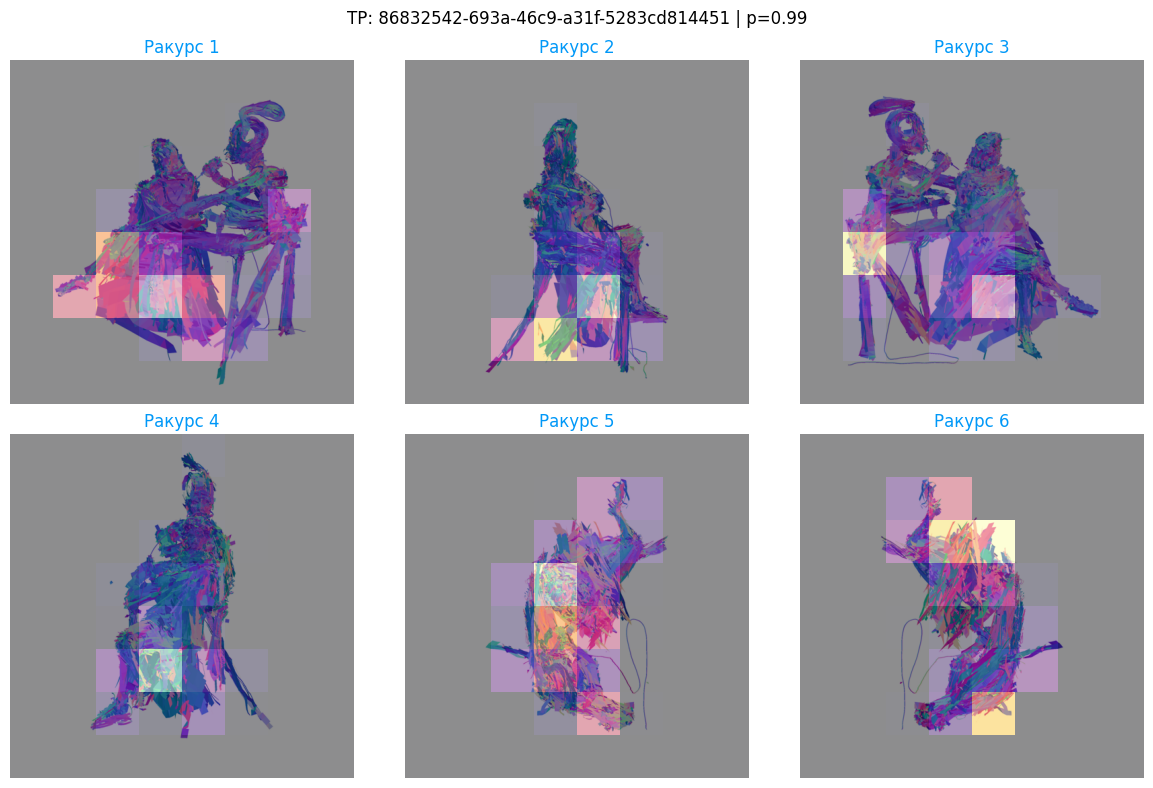

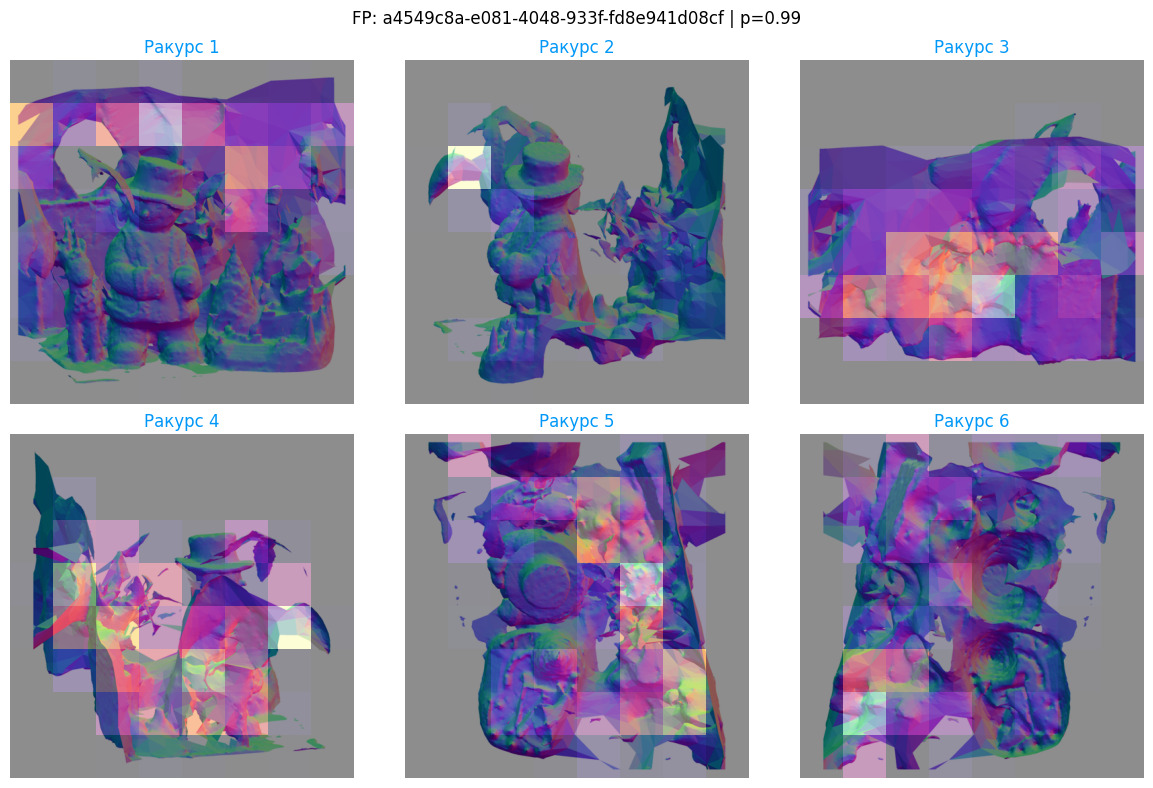

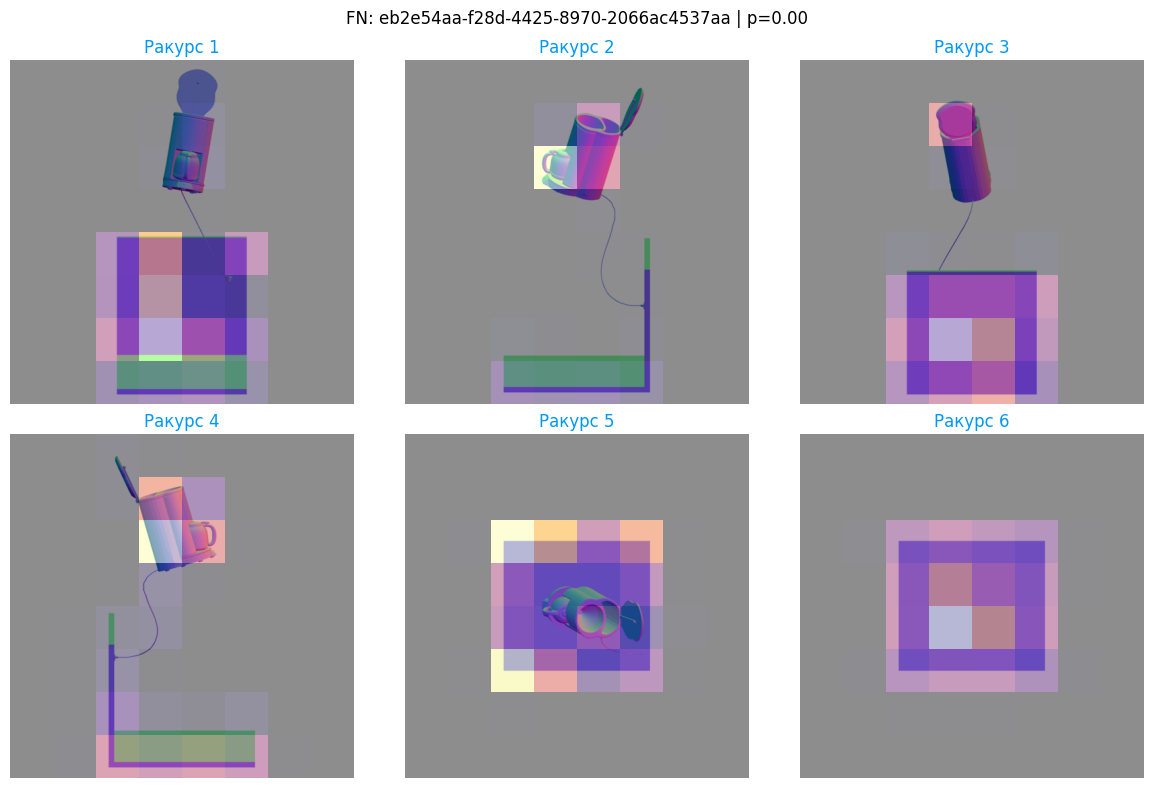

In [ ]:
best_name = metrics.sort_values('F1', ascending=False).iloc[0]['pooling']
best = models[best_name].to(device).eval()
threshold = float(metrics.set_index('pooling').loc[best_name, 'threshold'])
review = val[['item_id', 'artifacts', 'noisy']].copy()
review['probability'] = probabilities[best_name].to_numpy()
review['prediction'] = (review.probability >= threshold).astype(int)

def show_attention(position, label):
    item_id = val.item_id.iloc[position]
    x, _ = TokenDataset([len(train) + position])[0]
    with torch.inference_mode():
        _, heat = best(x.unsqueeze(0).to(device))
    heat = heat[0].cpu().numpy().reshape(6, 8, 8)
    heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
    with Image.open(TRAIN_DIR / f'{item_id}.png') as image:
        views = split_views(image)
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(views[i])
        ax.imshow(heat[i], extent=(0, views[i].width, views[i].height, 0),
                  cmap='inferno', alpha=.45, interpolation='nearest')
        ax.set_title(f'Ракурс {i + 1}', color='#0098F8')
        ax.axis('off')
    fig.suptitle(f'{label}: {item_id} | p={review.probability.iloc[position]:.2f}')
    plt.tight_layout()
    plt.show()

for label, mask, ascending in [
    ('TP', (review.artifacts == 1) & (review.prediction == 1), False),
    ('FP', (review.artifacts == 0) & (review.prediction == 1), False),
    ('FN', (review.artifacts == 1) & (review.prediction == 0), True),
]:
    rows = review[mask].sort_values('probability', ascending=ascending)
    if len(rows):
        show_attention(rows.index[0], label)

## Первый результат

Attention дала F1 **0.3776** против **0.3717** у DINOv2 + геометрии. Ложных срабатываний меньше: 94 вместо 119. Но пропусков больше: 28 вместо 23, а AP снизился с 0.2724 до 0.2372. Поэтому уверенного улучшения пока нет.

Все головы оценивались только после пятой эпохи. Теперь проверим, не была ли attention лучше раньше.

## 7. Attention: проверка после каждой эпохи

Оставляем те же пять эпох и параметры. Голова создаётся заново, прошлые веса не продолжаем обучать. После каждой эпохи считаем validation loss и AP.

$$e^*=\arg\max_e AP_{val}(e).$$

Эпоху выбираем по AP: он оценивает порядок вероятностей без выбора порога. Порог по F1 подберём один раз для выбранной головы. Patch-признаки прежние; test не используем. Новые файлы сохраняются отдельно от первого опыта.

In [ ]:
EPOCHS = 5
epoch_out = ROOT / 'labels/artifacts/models/mil_attention_epochs'
epoch_out.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED)
epoch_head = MILHead('attention').to(device)
epoch_optimizer = torch.optim.AdamW(epoch_head.parameters(), lr=1e-3, weight_decay=1e-4)
epoch_loader = DataLoader(TokenDataset(train_positions), batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
y_val = val.artifacts.to_numpy()
history_rows = []
best_ap = -1
best_state = None
best_probability = None
best_epoch = None

for epoch in range(1, EPOCHS + 1):
    epoch_head.train()
    train_total = 0
    for x, y in tqdm(epoch_loader, desc=f'Attention {epoch}/{EPOCHS}', leave=False):
        x, y = x.to(device), y.to(device)
        epoch_optimizer.zero_grad()
        logits, _ = epoch_head(x)
        loss = criterion(logits, y)
        loss.backward()
        epoch_optimizer.step()
        train_total += loss.item() * len(y)

    epoch_head.eval()
    val_total = 0
    batches = []
    with torch.inference_mode():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            logits, _ = epoch_head(x)
            val_total += criterion(logits, y).item() * len(y)
            batches.append(logits.sigmoid().cpu().numpy())
    probability = np.concatenate(batches)
    ap = average_precision_score(y_val, probability)
    history_rows.append({
        'epoch': epoch,
        'train_loss': train_total / len(epoch_loader.dataset),
        'val_loss': val_total / len(val_loader.dataset),
        'AP': ap,
        'F1_at_0.5': f1_score(y_val, probability >= .5, zero_division=0),
    })
    if ap > best_ap:
        best_ap = float(ap)
        best_epoch = epoch
        best_state = {name: value.detach().cpu().clone() for name, value in epoch_head.state_dict().items()}
        best_probability = probability.copy()
    pd.DataFrame(history_rows).to_csv(epoch_out / 'history.csv', index=False)
    print(f'Epoch {epoch}: train={history_rows[-1]["train_loss"]:.4f} | '
          f'val={history_rows[-1]["val_loss"]:.4f} | AP={ap:.4f}')

epoch_head.load_state_dict(best_state)
epoch_head.eval()
history = pd.DataFrame(history_rows)
display(history.round(4))
print('Выбрана эпоха:', best_epoch, '| AP:', round(best_ap, 4))

Epoch 1: train=1.0911 | val=0.9208 | AP=0.2296


Epoch 2: train=0.9235 | val=0.8987 | AP=0.2538


Epoch 3: train=0.8289 | val=0.9172 | AP=0.2543


Epoch 4: train=0.7308 | val=0.9674 | AP=0.2536


Epoch 5: train=0.6489 | val=0.9985 | AP=0.2487


,epoch,train_loss,val_loss,AP,F1_at_0.5
0,1,1.0911,0.9208,0.2296,0.2090
1,2,0.9235,0.8987,0.2538,0.2667
2,3,0.8289,0.9172,0.2543,0.2356
3,4,0.7308,0.9674,0.2536,0.2795
4,5,0.6489,0.9985,0.2487,0.2799


Выбрана эпоха: 3 | AP: 0.2543


## 8. Loss и AP

Смотрим, продолжает ли улучшаться validation, когда train loss падает. Отмеченная эпоха выбрана по AP, а не по минимальному train loss.

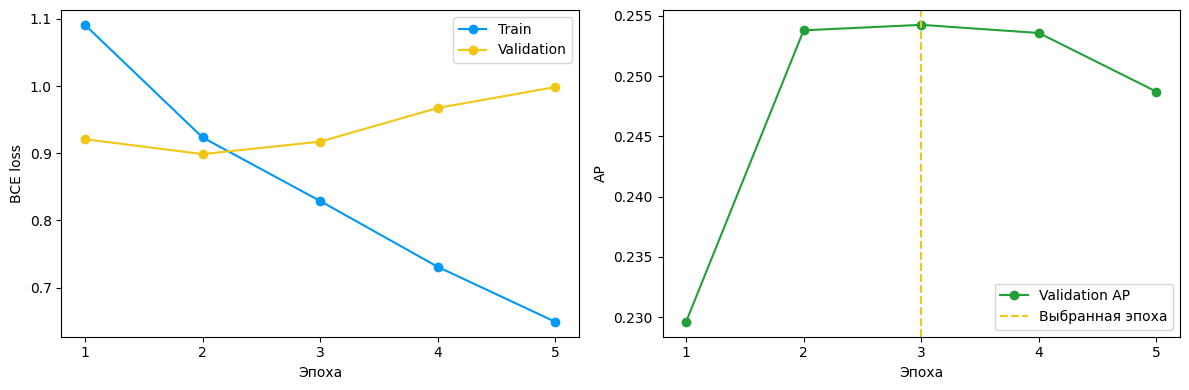

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.epoch, history.train_loss, marker='o', color='#0098F8', label='Train')
axes[0].plot(history.epoch, history.val_loss, marker='o', color='#F2C614', label='Validation')
axes[0].set(xlabel='Эпоха', ylabel='BCE loss')
axes[0].legend()
axes[1].plot(history.epoch, history.AP, marker='o', color='#21A038', label='Validation AP')
axes[1].axvline(best_epoch, color='#F2C614', linestyle='--', label='Выбранная эпоха')
axes[1].set(xlabel='Эпоха', ylabel='AP')
axes[1].legend()
for ax in axes:
    ax.set_xticks(history.epoch)
plt.tight_layout()
plt.show()

## 9. Порог и сравнение

$$\hat y=\mathbb{1}[p\ge t],\qquad t^*=\arg\max_t F1_{val}(t).$$

Сравниваем F1, AP и число ошибок. Рост F1 вместе с падением AP не считаем однозначным выигрышем. Эпоха и порог выбраны на одной validation, поэтому это всё ещё исследовательская оценка.

In [ ]:
epoch_threshold = float(max(np.arange(.01, 1, .01),
                            key=lambda t: f1_score(y_val, best_probability >= t, zero_division=0)))
predicted = best_probability >= epoch_threshold
tn, fp, fn, tp = confusion_matrix(y_val, predicted, labels=[0, 1]).ravel()
epoch_result = {
    'Model': 'Attention, best AP epoch', 'epoch': best_epoch,
    'F1': f1_score(y_val, predicted, zero_division=0), 'AP': best_ap,
    'Precision': precision_score(y_val, predicted, zero_division=0),
    'Recall': recall_score(y_val, predicted, zero_division=0),
    'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn),
    'threshold': epoch_threshold,
}
comparison = pd.DataFrame([
    {'Model': 'DINOv2 + geometry', 'F1': .3717, 'AP': .2724, 'FP': 119, 'FN': 23, 'threshold': .08},
    {'Model': 'Attention, first run', 'epoch': 5, 'F1': .3776, 'AP': .2372, 'FP': 94, 'FN': 28, 'threshold': .83},
    epoch_result,
])
display(comparison.round(4))

torch.save({'state_dict': best_state, 'pooling': 'attention', 'epoch': best_epoch,
            'threshold': epoch_threshold, 'validation_ap': best_ap,
            'seed': SEED, 'patch_meta': meta}, epoch_out / 'best_attention.pth')
pd.DataFrame([epoch_result]).to_csv(epoch_out / 'metrics.csv', index=False)
epoch_predictions = val[['item_id', 'artifacts']].copy()
epoch_predictions['probability'] = best_probability
epoch_predictions['prediction'] = predicted.astype(int)
epoch_predictions.to_csv(epoch_out / 'validation_probabilities.csv', index=False)
comparison.to_csv(epoch_out / 'comparison.csv', index=False)

,Model,F1,AP,FP,FN,threshold,epoch,Precision,Recall,TP,TN
0,DINOv2 + geometry,0.3717,0.2724,119,23,0.08,NaN,NaN,NaN,NaN,NaN
1,"Attention, first run",0.3776,0.2372,94,28,0.83,5.0,NaN,NaN,NaN,NaN
2,"Attention, best AP epoch",0.3363,0.2543,123,27,0.75,3.0,0.236,0.5846,38.0,1173.0


## Что получилось

На 3-й эпохе AP вырос до **0.2543**, но F1 получился **0.3363**. У первого Attention F1 был **0.3776**, у DINOv2 + геометрии — **0.3717**. Поэтому ранняя остановка по AP не улучшила F1 для `artifacts`.

## 10. Сравниваем ошибки двух моделей

Проверяем, на каких объектах Attention и DINOv2 + геометрия ошибаются по-разному. Для быстрой проверки объединяем их готовые ответы через **ИЛИ** и **И**. Пороги берём из предыдущих опытов, новые модели не обучаем.

Это сравнение на той же validation, поэтому его F1 может быть оптимистичным.

In [ ]:
geometry_dir = ROOT / 'labels/artifacts/models/dinov2'
geometry_file = geometry_dir / 'validation_probabilities.csv'
metrics_file = geometry_dir / 'metrics.csv'

if geometry_file.is_file() and metrics_file.is_file():
    geometry = pd.read_csv(geometry_file)
    geometry_metrics = pd.read_csv(metrics_file)
    joined = val[['item_id', 'artifacts']].merge(
        geometry[['item_id', 'artifacts', 'DINOv2_geometry']],
        on='item_id', how='left', validate='one_to_one', suffixes=('', '_saved')
    )
    assert len(joined) == len(val) and joined.DINOv2_geometry.notna().all()
    assert (joined.artifacts == joined.artifacts_saved).all()

    geometry_threshold = float(geometry_metrics.set_index('Model').loc['DINOv2_geometry', 'Threshold'])
    geometry_prediction = joined.DINOv2_geometry.to_numpy() >= geometry_threshold
    attention_prediction = predicted

    rows = []
    for name, answer in [
        ('DINOv2 + geometry', geometry_prediction),
        ('Attention', attention_prediction),
        ('ИЛИ', geometry_prediction | attention_prediction),
        ('И', geometry_prediction & attention_prediction),
    ]:
        tn, fp, fn, tp = confusion_matrix(y_val, answer, labels=[0, 1]).ravel()
        rows.append({'Модель': name, 'F1': f1_score(y_val, answer),
                     'Precision': precision_score(y_val, answer, zero_division=0),
                     'Recall': recall_score(y_val, answer, zero_division=0),
                     'FP': int(fp), 'FN': int(fn)})

    error_comparison = pd.DataFrame(rows)
    display(error_comparison.round(4))
    print('Пропуски геометрии, найденные Attention:',
          int(((y_val == 1) & ~geometry_prediction & attention_prediction).sum()))
    print('Новые ложные срабатывания при ИЛИ:',
          int(((y_val == 0) & ~geometry_prediction & attention_prediction).sum()))
    error_comparison.to_csv(epoch_out / 'error_comparison.csv', index=False)
else:
    print('Сравнение с DINOv2 + геометрией пропущено: на Drive нет его validation_probabilities.csv и metrics.csv')